# - Introduction

Les déplacements forcés de populations constituent l'un des enjeux géopolitiques et humanitaires majeurs du XXIe siècle. Selon les données du Haut-Commissariat des Nations Unies pour les réfugiés (UNHCR), des millions de personnes sont contraintes chaque année de quitter leur pays d'origine en raison de conflits armés, de persécutions ou d'instabilités politiques. Parmi les grandes régions émettrices mondiales, l'Asie du Sud occupe une place singulière : marquée par des crises prolongées — notamment en Afghanistan, au Pakistan ou encore au Sri Lanka — et par l'exode massif des Rohingyas à partir de 2017, cette région combine à la fois un volume très élevé de demandeurs d'asile et une forte diversité de pays de destination à travers le monde.

Au-delà de l'urgence humanitaire, la répartition géographique de ces flux soulève d'importantes questions économiques et institutionnelles quant aux mécanismes qui gouvernent le choix d'un pays d'accueil. Si les modèles de gravité appliqués aux migrations mettent traditionnellement en avant le rôle central de la proximité géographique et des coûts de transport, les trajectoires des demandeurs d'asile répondent également à des logiques plus complexes : attractivité économique des pays de destination, présence d'un cadre juridique d'asile structuré, proximité culturelle ou linguistique, et liens historiques. L'étude de la période **2017–2020** offre à cet égard un cadre d'observation privilégié : elle permet d'analyser ces déterminants structurels sur quatre années consécutives, avant les bouleversements majeurs induits par les restrictions de mobilité liées à la crise sanitaire puis par les ruptures géopolitiques de 2021.

Ainsi, nous pouvons nous poser la question suivante : **quels sont les facteurs géographiques, économiques et culturels qui déterminent le choix du pays de destination des demandeurs d'asile originaires d'Asie du Sud ?** Plus précisément, la proximité géographique et la richesse du pays d'accueil suffisent-elles à expliquer l'orientation des flux, ou d'autres variables — telles que le partage d'une frontière, d'une langue commune ou de liens coloniaux — jouent-elles un rôle déterminant ?

Ici, nous considérerons que les mouvements migratoires étudiés correspondent aux **nouvelles demandes d'asile** enregistrées annuellement par l'UNHCR entre 2017 et 2020. De plus, nous mesurerons le choix d'une destination par la **part des demandes d'asile** d'un pays d'origine qui s'y dirige (`destination_share`), et nous évaluerons l'influence des facteurs explicatifs en croisant ces flux avec les variables bilatérales de la base *CEPII Gravity* (distance pondérée entre pays, PIB par habitant, contiguïté géographique, langue officielle commune, proximité religieuse et passé colonial).


### Sommaire

- **I. Données et préparation de la base**
    - A. Les données UNHCR
    - B. Les données CEPII Gravity
    - C. Jointure, nettoyage des doublons et construction de `destination_share`
    - D. Limites sur les données

- **II. Vue macroscopique et focus sur l'Asie du Sud**
    - A. Vue macro : volume de demandes d'asile et diversité des destinations par région
        - _1. Statistiques descriptives globales_
        - _2. Comparaison interrégionale et justification du choix de l'Asie du Sud_
    - B. Focus sur l'Asie du Sud
        - _1. Cartographie mondiale des principaux flux migratoires (2017-2020)_
        - _2. Volume et diversité des destinations pour les 9 pays de la région_
        - _3. Principales destinations par pays d'origine (`destination_shares`)_

- **III. Étude des facteurs déterminant le choix de destination**
    - A. Richesse du pays d'accueil (`gdpcap_d`) : les destinations les plus riches reçoivent-elles davantage de flux ?
    - B. Distance géographique (`distw_harmonic`) : les destinations les plus proches reçoivent-elles davantage de flux ?
        - _1. Régression linéaire simple sur les variables brutes_
        - _2. Passage au modèle log-log_
        - _3. Interprétation économique et limites méthodologiques_
    - C. Proximité linguistique et facteurs culturels ou frontaliers
        - _1. Langue officielle commune (`comlang_off`)_
        - _2. Proximité religieuse (`comrelig`), effet frontière (`contig`) et liens coloniaux (`col_dep_ever`)_
    - D. Synthèse et mise en perspective avec la littérature

- **Conclusion**

# I - Données

## A. Les données UNHCR

L'Agence des Nations Unies pour les réfugiés (UNHCR) met à disposition plusieurs bases de données relatives aux déplacements forcés de population.
Dans le cadre de cette étude, une première source de données est récupérée à partir de l'API de l'UNHCR. L'endpoint consacré aux pays permet notamment d'obtenir les informations suivantes :
- le nom du pays ;
- son code ISO alpha-3, norme internationale permettant d'identifier chaque pays ;
- la région du monde à laquelle il appartient.

Une seconde source de données de l'UNHCR, disponible sous la forme d'un fichier Excel, est utilisée pour mesurer les déplacements entre pays. Elle contient des observations par pays d'origine, pays de destination et année.
Les variables retenues sont :
- le pays d'origine et son code ISO ;
- le pays de destination et son code ISO ;
- l'année ;
- le type de population ou de mouvement (PT) ;
- le nombre d'observations correspondant (Count).

L'objectif de l'étude étant d'analyser la répartition géographique des nouvelles demandes d'asile, seules les observations pour lesquelles PT = ASY sont conservées. Dès lors, la variable Count correspond au nombre de nouvelles demandes d'asile enregistrées pour un pays d'origine, un pays de destination et une année donnés.
Aussi, la variable Count ne doit pas être interprétée comme un nombre d'individus uniques : une même personne peut déposer une demande d'asile dans plusieurs pays au cours de son parcours. L'analyse porte donc sur la distribution des nouvelles demandes d'asile entre pays de destination, et non sur des choix individuels uniques.

Les données sont ensuite nettoyées afin d'homogénéiser les types des différentes variables, et seules les observations comprises entre 2017 et 2020 sont conservées.
Enfin, les informations géographiques obtenues via l'API sont jointes aux données relatives aux demandes d'asile grâce aux codes ISO des pays. Cette étape permet notamment d'associer à chaque pays d'origine sa région du monde.
On obtient ainsi le jeu de données `unhcr_df`, qui constitue la base UNHCR utilisée pour la suite de l'analyse.

## B. Les données CEPII Gravity

Le Centre d’études prospectives et d’informations internationales (CEPII) est un organisme de recherche indépendant français étudiant l’économie internationale. Il a mis à disposition diverses bases de données, et notamment la database gravity, qui recense pour chaque paire de pays et chaque année entre 1948 et 2020 diverses informations utiles pour étudier leurs relations économiques. Nous avons utilisé les variables suivantes dans notre analyse:

- l’année de l’observation ;
- les codes ISO3 des deux pays étudiés ;
- les PIB par habitants des pays étudiés ;
- la distance harmonique pondérée entre les deux pays.

Après conservation des observations entre 2017 et 2020, nettoyage des données et harmonisation des noms et types de variables entre les bases, nous avons joint la database unhcr_df et les données provenant de gravity pour former la database south_asia, utilisée pour la suite de l’analyse. 


In [1]:
# Collecte et manipulation de données
%pip install -q -r requirements.txt
import requests
import numpy as np
import pandas as pd

# Cartographie et visualisation
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import FancyArrowPatch
import plotly.express as px

# Modélisation
from sklearn.linear_model import LinearRegression

# Récupération des fonctions

from plots import (plot_carte_flux,plot_regression_distance_simple,plot_regression_distance_log)
from analyse import (charger_south_asia,charger_destination_shares,scatter_plot_pib_demandes_asile,scatter_plot_ech_log,reg_lin_log_log)

south_asia = charger_south_asia()
print(south_asia.head(3))


Statistiques descriptives globales
Nombre total de nouvelles demandes d'asile : 6565910
Nombre de pays d'origine distincts : 197
Nombre de pays de destination distincts : 167
Nombre de régions d'origine : 23
Part de demandeurs d'asile venant d'Asie du Sud : 13.6 %
Part des demandeurs d'asile sud-asiatiques originaires d'Afghanistan : 46.4 %
Médiane du nombre moyen de destinations des demandeurs d'asile sud-asiatiques hors Afghanistan : 43.125
Nombre moyen de destinations pour l'Afghanistan : 66.5
(1427, 6)
(1780, 13)
6
(1427, 6)
(1780, 13)
  coo_iso     coo_name coa_iso   coa_name  year  refugees  distw_harmonic  \
0     AFG  Afghanistan     ALB    Albania  2017        29          4250.0   
1     AFG  Afghanistan     ARG  Argentina  2017         7         15283.0   
2     AFG  Afghanistan     ARM    Armenia  2017         5          2163.0   

  contig comlang_off  comrelig col_dep_ever  gdpcap_o  gdpcap_d  \
0  False       False     0.204        False     2.058    12.771   
1  False   

# II. Vue macroscopique et focus sur l'Asie du Sud

## A. Vue macro : volume de demandes d'asile et diversité des destinations par région
### 1. Statistiques descriptives globales

Entre 2017 et 2020, l’UNHCR recense 6 565 910 nouvelles demandes d’asile enregistrées dans 167 pays de destination. Ces demandes concernent des personnes originaires de 197 pays différents, regroupés par l’UNHCR en 23 régions d’origine.


In [2]:
# Chargement des données UNHCR nettoyées depuis le stockage Onyxia
unhcr_df = pd.read_parquet("https://minio.lab.sspcloud.fr/angelik/ProjetRefugies/unhcr_df.parquet")

# Calculs de statistiques descriptives globales

n_applications = unhcr_df["refugees"].sum()
nunique_coo = unhcr_df["coo_name"].nunique()
nunique_coa = unhcr_df["coa_name"].nunique()
nunique_region = unhcr_df["region_origin"].nunique()


print("Statistiques descriptives globales")
print("Nombre total de nouvelles demandes d'asile :", n_applications)
print("Nombre de pays d'origine distincts :", nunique_coo)
print("Nombre de pays de destination distincts :", nunique_coa)
print("Nombre de régions d'origine :", nunique_region)

Statistiques descriptives globales
Nombre total de nouvelles demandes d'asile : 6565910
Nombre de pays d'origine distincts : 197
Nombre de pays de destination distincts : 167
Nombre de régions d'origine : 23


Afin d’étudier les facteurs associés aux destinations des demandeurs d’asile, l’analyse a ensuite été restreinte aux individus provenant d’une même région d’origine. Le choix de cette région repose sur deux critères :
- un nombre important de nouvelles demandes d’asile ;
- une forte diversité des pays de destination.

Le graphique suivant permet de comparer les différentes régions selon ces deux dimensions. L’axe des abscisses représente le nombre moyen de pays de destination, calculé à partir des couples (pays d’origine, année). L’axe des ordonnées représente quant à lui le nombre total de nouvelles demandes d’asile enregistrées entre 2017 et 2020 pour chaque région d’origine.

In [18]:
import plots
plots.world_scatter_plot()

L’Afrique du Nord présente le nombre moyen de destinations le plus élevé, avec environ 40,3 pays de destination, tandis que l’Amérique du Sud est la région comptabilisant le plus grand nombre de nouvelles demandes d’asile, avec 1 240 486 demandes sur la période 2017-2020.

L’Asie du Sud a finalement été retenue car elle combine des valeurs élevées pour ces deux indicateurs. Elle comptabilise 892 851 nouvelles demandes d’asile, ce qui la place au troisième rang des régions en termes de volume, tout en atteignant environ 40 pays de destination en moyenne, soit le deuxième niveau le plus élevé de l’échantillon.

In [30]:
from analyse_preliminaire import create_overview
overview = create_overview(unhcr_df)

south_asia_share = (overview[overview["region_origin"] == "Southern Asia"]["refugees"].iloc[0] 
                    / n_applications)*100

print("Part de demandeurs d'asile venant d'Asie du Sud :", round(south_asia_share, 2), "%")


Part de demandeurs d'asile venant d'Asie du Sud : 13.6 %


Les demandes provenant d’Asie du Sud représentent ainsi environ 13,6 % de l’ensemble des nouvelles demandes d’asile recensées dans notre base entre 2017 et 2020. Cette combinaison d’un volume important et d’une forte diversité des destinations en fait une région particulièrement adaptée à l’étude des facteurs susceptibles d’être associés au choix du pays de destination.

## B. Focus sur l'Asie du Sud
### 1. Cartographie mondiale des principaux flux migratoires (2017-2020)



In [36]:
plot_carte_flux(south_asia)


Cette carte représente les principaux corridors de nouvelles demandes d'asile originaire d'Asie du Sud cumulés sur la période (2017-2020) (projection mondiale WGS). Par soucis de lisibilité; seuls les couples origine-destination dépassant un seuil de 5000 demandes cumulées sont affichés. Chaque pays d'émission d'Asie du Sud (surligné en rose sur le fond de carte) estidentifié par une couleur répertoriée dans la légende en bas à gauche. L'épaisseur est proportionnelle au volume totale de demande d'asile.

La carte met en évidence que d'une part, les flèches les plus épaisses correspondent à des déplacements vers des pays proches ou situés sur des routes de transits (notamment depuis l'Afghanistan et l'Iran vers la Turquie), traduisant le poids de l'urgence et de la proximité géographique. D'autre part, on remarque une projection vers des pôles occidentaux malgré la distance, en direction de l'Europe de l'Ouest (Allemagne, France...), de l'Amérique du Nord (États-Unis, Canada) et de l'Australie.

### 2. Volume et diversité des destinations pour les 9 pays de la région

In [37]:
from plots import south_asia_scatter_plot
south_asia_scatter_plot()

Si l’on étudie le même graphique que précédemment, mais cette fois-ci à l’échelle de l’Asie du Sud, le constat premier est que les réfugiés afghans sont surreprésentés dans cette cohorte. En effet, l’UNHCR comptabilise 414, 284 nouvelles demandes d’asile entre 2017 et 2020 ce qui correspond à 46.4% du nombre total de réfugiés venant d’Asie du Sud. 

In [38]:
from analyse_preliminaire import create_overview_south_asia
overview_southasia = create_overview_south_asia(unhcr_df)

# Calcul de la part des nouvelles demandes d'asile provenant
# d'Afghanistan parmi l'ensemble des demandes originaires d'Asie du Sud.
afghanistan_share = (overview_southasia[overview_southasia["coo_name"] == "Afghanistan"]["refugees"].iloc[0]/
                    (overview_southasia["refugees"].sum()))*100

print("Part des demandeurs d'asile sud-asiatiques originaires d'Afghanistan :",
      round(afghanistan_share, 2), "%")

Part des demandeurs d'asile sud-asiatiques originaires d'Afghanistan : 46.4 %


Et ces réfugiés demandent asile dans environ 66.5 pays différents ce qui est bien supérieur à la médiane obtenue avec les 8 autres pays hors Afghanistan de 47,9 pays.

In [39]:
overview_southasia = create_overview_south_asia(unhcr_df)

# Calcul de la part des nouvelles demandes d'asile provenant
# d'Afghanistan parmi l'ensemble des demandes originaires d'Asie du Sud.
afghanistan_share = (overview_southasia[overview_southasia["coo_name"] == "Afghanistan"]["refugees"].iloc[0]/
                    (overview_southasia["refugees"].sum()))*100

print("Part des demandeurs d'asile sud-asiatiques originaires d'Afghanistan :",
      round(afghanistan_share, 2), "%")


# Conservation des pays d'Asie du Sud hors Afghanistan afin de comparer
# la diversité de leurs destinations à celle de l'Afghanistan.
overview_southasia_without_afghanistan = overview_southasia[
                                        overview_southasia["coo_name"] != "Afghanistan"
                                        ]

# Calcul de la médiane du nombre moyen de destinations
# pour les pays d'Asie du Sud hors Afghanistan.
median_destinations = (overview_southasia_without_afghanistan[
                        "mean_destination_countries"
                        ].median())

print(
    "Médiane du nombre moyen de destinations des demandeurs d'asile sud-asiatiques hors Afghanistan :",
    median_destinations)


# Calcul du nombre moyen de destinations pour l'Afghanistan
# afin de le comparer à la médiane des autres pays de la région.
afghanistan_destinations = (overview_southasia[
                            overview_southasia["coo_name"] == "Afghanistan"
                            ]["mean_destination_countries"].iloc[0])

print(
    "Nombre moyen de destinations pour l'Afghanistan :",
    afghanistan_destinations)

Part des demandeurs d'asile sud-asiatiques originaires d'Afghanistan : 46.4 %
Médiane du nombre moyen de destinations des demandeurs d'asile sud-asiatiques hors Afghanistan : 43.125
Nombre moyen de destinations pour l'Afghanistan : 66.5


### 3. Principales destinations par pays d'origine (`destination_shares`)

L’étude des principales destinations met en évidence une forte hétérogénéité des profils migratoires au sein de l’Asie du Sud. Les demandes d’asile ne se répartissent pas de manière uniforme entre les pays de destination : certains pays d’origine présentent des flux très concentrés vers une destination dominante, tandis que d’autres se caractérisent par une répartition plus diffuse.

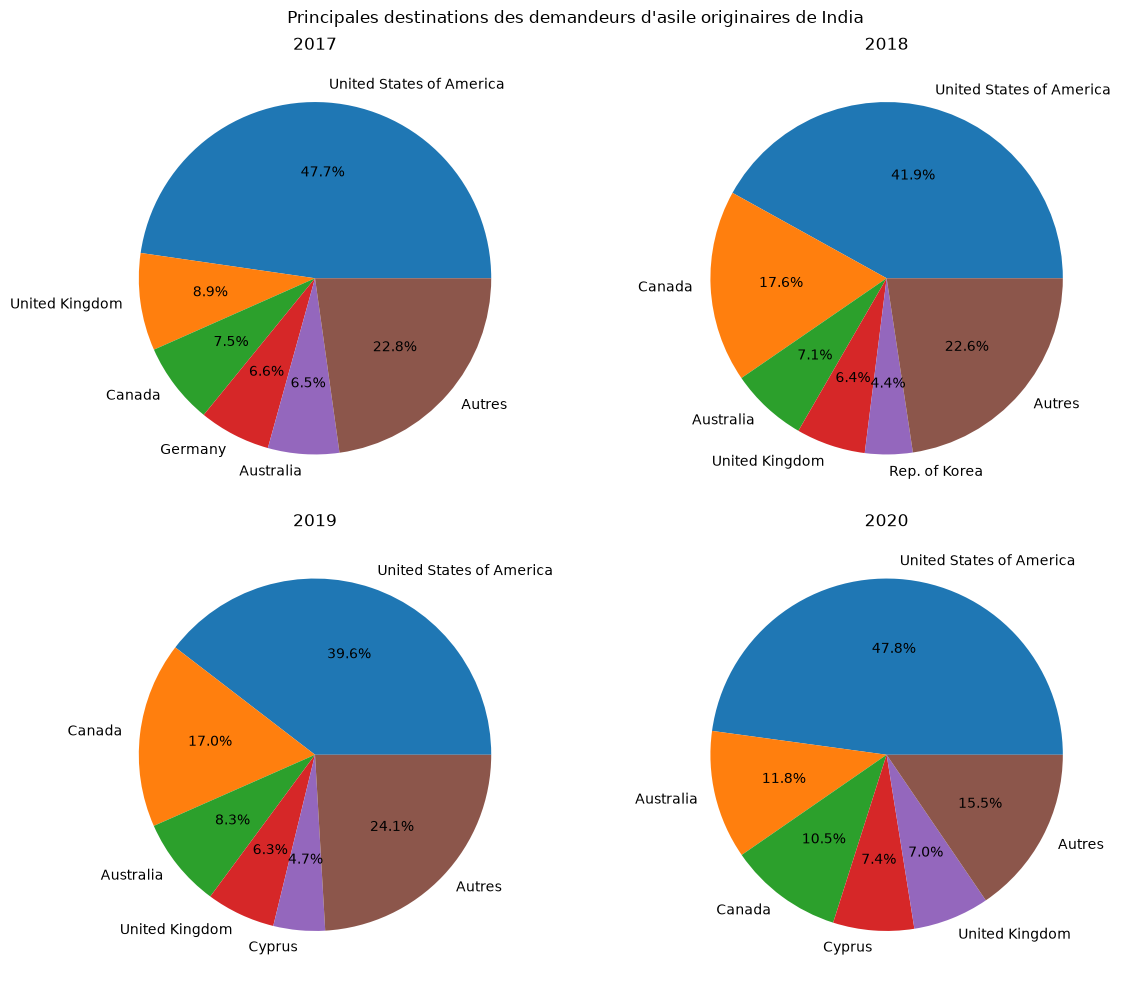

In [40]:
from plots import plot_destinations
plot_destinations("India")

- Une première tendance apparaît pour l’**Afghanistan** et l’**Iran**, où la Turquie occupe initialement une place importante, mais dont le poids diminue nettement au cours de la période. Pour l’Afghanistan, la Turquie représente plus de la moitié des demandes en 2017, contre moins de 30 % en 2020, tandis que la Grèce, la France et l’Allemagne prennent progressivement davantage de poids. Une évolution comparable est observée pour l’Iran : la part de la Turquie diminue progressivement alors que l’Allemagne et surtout le Royaume-Uni deviennent des destinations majeures.  Dès lors, ces deux cas semblent traduire le passe d’une forte concentration sur une destination géographiquement proche à une répartition plus importante entre pays européens.

- À l’inverse, l’**Inde** présente une structure particulièrement stable. Les États-Unis demeurent de loin la première destination sur l’ensemble de la période et représentent chaque année environ 40 % à 48 % des demandes. Les autres principales destinations sont essentiellement des pays anglophones, notamment le Canada, l’Australie et le Royaume-Uni. Aussi, on peut faire l’hypothèse que cette proximité linguistique de ces pays avec l’Inde pourrait expliquer cette répartition des demandes.

- Le **Pakistan** et le **Bangladesh** présentent davantage une orientation vers plusieurs destinations européennes. Pour le Pakistan, l’Italie et la Grèce restent parmi les principales destinations pendant toute la période. La part importante de la catégorie « Autres » indique également une dispersion relativement forte entre plusieurs destinations secondaires. Au Bangladesh, la structure évolue davantage : l’Italie domine très nettement en 2017, puis son importance diminue alors que la France prend progressivement une place centrale et devient la première destination en fin de période.

- Le **Népal** présente encore une autre configuration. Entre 2017 et 2019, les États-Unis et le Japon concentrent ensemble une part importante des demandes. En 2020, cette structure se modifie : les États-Unis restent la première destination, mais le Japon disparaît des principales destinations au profit notamment de Chypre, de la Corée du Sud et de l’Australie. Le **Sri Lanka** présente lui aussi une forte diversification : le Japon et l’Australie occupent une place importante au début de la période, tandis que la France devient progressivement l’une des destinations principales. Par ailleurs, la part élevée de la catégorie « Autres » révèle que les demandes sri-lankaises sont réparties entre un nombre relativement important de destinations.

- Enfin, les cas du **Bhoutan** et des **Maldives** se distinguent par une concentration particulièrement forte des demandes sur un très petit nombre de pays. Pour le Bhoutan, les États-Unis représentent la quasi-totalité des destinations observées sur la période. Pour les Maldives, les demandes sont également concentrées sur une ou deux destinations selon les années, notamment le Sri Lanka, le Royaume-Uni, les Pays-Bas ou l’Australie.




Dans l’ensemble, trois grands profils semblent donc apparaître: des pays dont les demandes sont initialement concentrées vers une destination proche avant de se diversifier vers l’Europe, comme l’Afghanistan et l’Iran ; des pays présentant une forte orientation vers des destinations anglophones relativement stable, comme l’Inde ; et des pays dont les demandes sont davantage réparties entre plusieurs destinations et évoluent sensiblement au cours du temps, comme le Pakistan, le Bangladesh, le Népal ou le Sri Lanka.

Ce constat constitue ainsi le point de départ de la suite de l’étude qui consiste à examiner si la distance géographique, la langue commune, la richesse du pays de destination et l’existence de liens historiques permettent d’expliquer une partie de ces différences.

# IV. Analyse des données

## A. Lien entre la distance géographique et le choix de destination

Afin d'évaluer l'influence de l'éloignement géographique sur la répartition des demandeurs d'asile originaires d'Asie du Sud entre 2017 et 2020 , nous nous servons du DataFrame south_asia et plus particulièrement des données “distw_harmonic” et “destination_share”. Le premier, partant de deux pays i et j et pour une année t donnée, donne le calcul de la moyenne harmonique des distances entre les principales agglomérations des deux pays, pondérée par le poids démographique respectif de chaque ville dans la population totale du pays. Le deuxième mesure la proportion des nouvelles demandes d'asile en provenance du pays i qui ont été déposées dans le pays j. Cet indicateur est filtré sur les nouvelles demandes d’asile (PT = = “ASY”).

### 1. Régression linéaire simple sur les variables brutes 

Dans un premier temps, nous estimons par les moindres carrés ordinaires le modèle linéaire suivant : 

$$\text{destination\_share}_{ijt} = \beta_0 + \beta_1\cdot \text{distw\_harmonicic}_{ij} + \varepsilon_{ijt}$$ 

L'estimation aboutit aux paramètres suivants :
Constante (0) : 0,0096 (soit une part prédite de 0.96 %  à distance nulle) ;
Pente (1) : +2,4310-6 ;
Coefficient de détermination (R2) : 0,0102 (soit 1.02 % de la variance expliquée).
Graphiquement, on obtient :

Modèle simple - Constante : 0.009611096742347957
Modèle simple - Pente : 2.434407971878744e-06
Modèle simple - R² : 0.010243794303354314


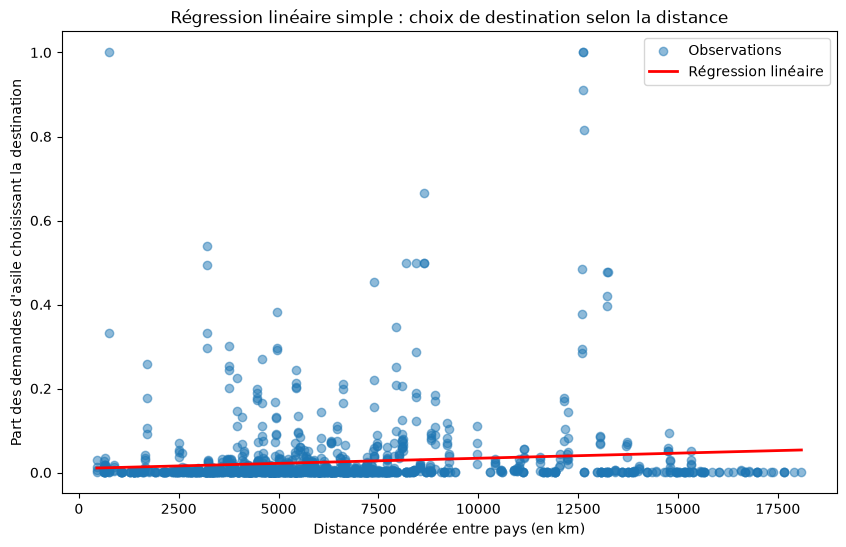

In [4]:
plot_regression_distance_simple(south_asia)


On remarque alors que la majorité de la distribution est écrasée près de l’axe des abscisses (proche de 0 % de demandeurs d’asile) tandis que quelques pays captent entre 20% et 100% des demandes. De plus, il est intéressant de noter que ces pics peuvent apparaître à courte (100 km) comme à longue distance ( 12500 km). Néanmoins avec un R2 de 1.02 %, la droite de régression reste presque horizontale et ne permet pas de donner un lien favorable entre distance et choix de destination. Pour ne pas avoir de données trop écrasées, il est intéressant de passer à une régression du type log-log.

### 2. Passage au modèle log-log 
Pour corriger l'écrasement des échelles, nous appliquons une transformation logarithmique aux deux variables :

(destination_shareijt)=0+1(distw_harmonicij)+ijt
Les résultats de cette seconde estimation sont les suivants :
Constante (0) : -8,761 ;
Pente / Élasticité (1) : +0,313 ;
Coefficient de détermination (R2) : 0,0075 (soit 0.75 % de la variance expliquée).


Modèle log-log - Constante : -8.761052514225707
Modèle log-log - Pente (élasticité) : 0.31297232487413107
Modèle log-log - R² : 0.007536927370070945


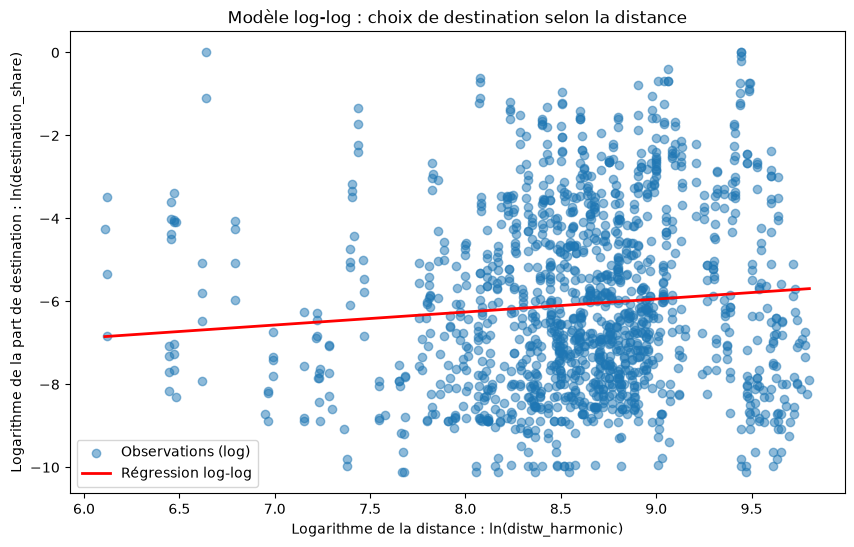

In [5]:
plot_regression_distance_log(south_asia)

Cette fois-ci, bien que le passage au logarithme permette d'étaler le nuage de points sur l'ensemble du plan, la qualité d'ajustement demeure très faible (R2 < 1%) et la pente estimée reste légèrement positive (+0,313).
Il est tout de même intéressant de noter que cette estimation repose sur tous les couples origine-destination ayant enregistré au moins une nouvelle demande d'asile entre 2017 et 2020 (refugees>0), une condition nécessaire à l'utilisation de la transformation logarithmique. Ce choix méthodologique écarte les pays n'accueillant aucun ressortissant d'Asie du Sud, dont l'inclusion tirerait mécaniquement la droite de régression vers l'axe horizontal Néanmoins, notre démarche ne vise pas à expliquer la probabilité d'ouverture d'un couloir migratoire, mais à comparer l'attractivité relative des pays qui constituent effectivement des destinations d'asile pour la région. L'étude mesure ainsi comment la distance géographique répartit les flux parmi les pays d'accueil réellement sollicités par les demandeurs d'asile.


### 3.Interprétation  

Contrairement à l’intuition standard qui nous dirait que la distance est un frein à l’immigration (notamment en raison de coûts de transports plus élevés et du changement de type de transports (avions, bâteau au lieu de la marche ou de la voiture),nos estimations ne font pas ressortir de relation négative entre éloignement et part des demandes d'asile. Ceci peut s’expliquer par différentes raisons : 
La spécificité d’une demande d’asile l'étude porte exclusivement sur les nouvelles demandes d'asile enregistrées et non sur les stocks globaux de réfugiés. Or, si les pays frontaliers d'Asie du Sud accueillent d'importants volumes de réfugiés sous d'autres statuts, les demandes d'asile individuelles formelles se dirigent massivement vers les pays occidentaux dotés de systèmes d'asile structurés, notamment l'Europe de l'Ouest et l’Amérique du Nord
L’absence de pondération par la taille des flux d’origine : dans la régression, chaque observation reçoit le même poids, ainsi certains pays d’origine qui enregistrent des demandes d'asiles concentrées sur peu de pays, de plus lointains ( comme Maldives avec États-Unis) tirent mécaniquement la droite de régression vers le haut.
Ainsi, la distance géographique seule ne détermine pas le choix des demandeurs d’asile, à distance comparable il faut s’intéresser à d’autres facteurs ( PIB du pays (gdpcap_d), proximité languistique ou histoire colonial) pour comprendre le choix du pays de refuge.


## B. Lien entre la richesse du pays d'accueil (`gdpcap_d`) et le nombre de demandes d'asile.
Afin d'évaluer l'influence du PIB la répartition des demandeurs d'asile originaires d'Asie du Sud entre 2017 et 2020 , nous nous servons du DataFrame south_asia et plus particulièrement des données “gdp” et “refugees_sum”. La première donnée correspond à la moyenne du PIB par habitant d’un pays sur la periode 2017-2020 (en milliers de US$), et la deuxième correspond au nombre de demandes d’asile reçues par un pays en provenance de l’Asie du Sud durant la periode 2017-2020. Il y a donc un point par pays de destination. Nous obtenons ce graphique:


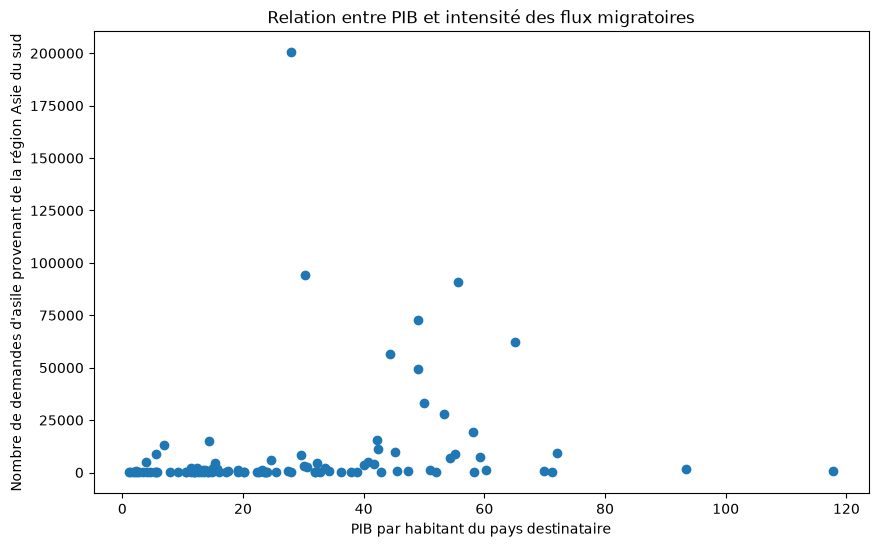

In [6]:
scatter_plot_pib_demandes_asile(south_asia)

Nous obtenons une distribution écrasée près de l’axe des abscisses, avec quelques pics, situés entre 25 et 70 milliers de dollars par habitant. Afin d’obtenir un graphe plus lisible, il est intéressant de passer à une échelle logarithmique:

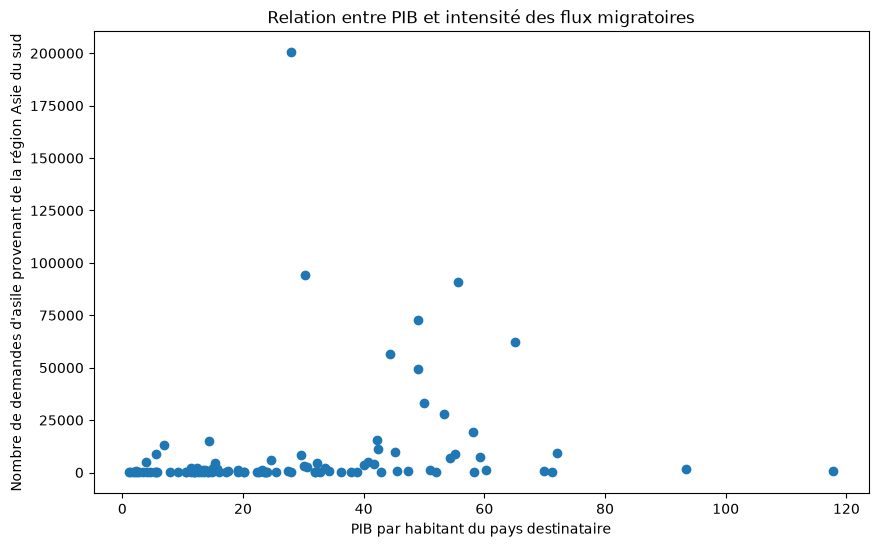

In [7]:
scatter_plot_ech_log(south_asia)

Ainsi, on semble observer une corrélation positive entre le PIB et le nombre de demandes d’asile. 
Afin d’obtenir une analyse plus précise de la situation, on réalise une régression linéaire sur les deux variables. On estime donc par les moindres carrés ordinaires le modèle suivant:

(refugees_sum)= c0+c1(gdp)+residu.

L'estimation aboutit aux paramètres suivants :

- Constante (c0) : 2.70638342  ;
- Pente / Élasticité (c1) : 1.19027949  ;
- Coefficient de détermination (R2) : 0.22363344458182455  (soit 22 % de la variance expliquée). Le pouvoir explicatif du modèle semble donc élevé.


Modèle log-log - Constante : [2.70638342]
Modèle log - Pente : [1.19027949]
Modèle log - R² : 0.22363344458182455


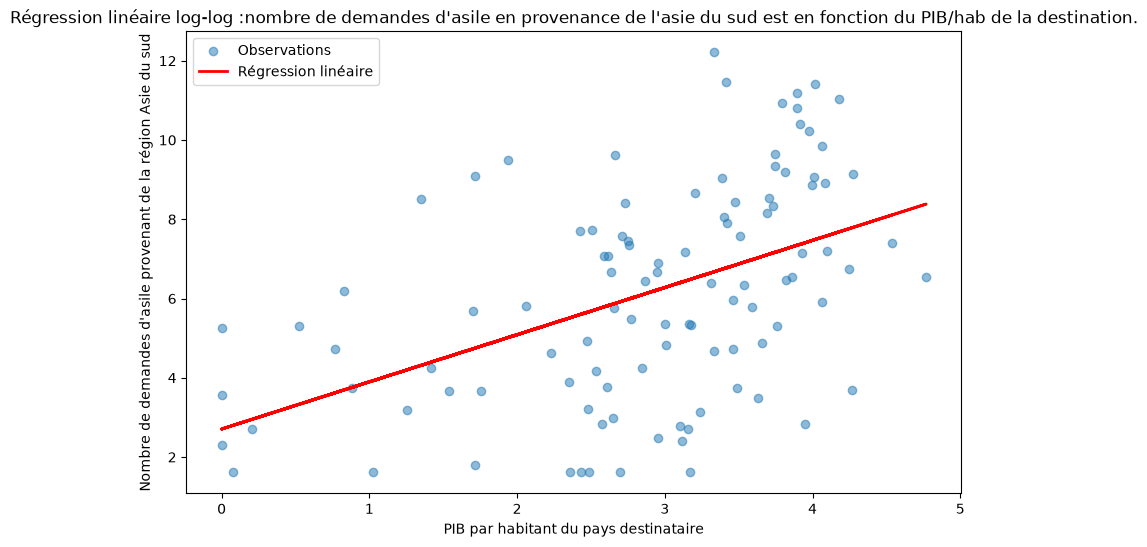

In [8]:
reg_lin_log_log(south_asia)

Ainsi, le modèle renforce l’hypothèse d’une corrélation positive entre le PIB par habitant et le nombre de demandes d’asile.

#### Interpretation:
Cette relation positive entre le nombre de demandes d’asile et le PIB/hab paraît intuitive. En effet, les pays ayant un fort PIB/hab offrent des meilleures conditions de vie et sont donc plus attractifs pour les réfugiés. De plus, les pays développés peuvent posséder des systèmes d’asile plus structurés, et accueillent donc plus de demandes d’asile individuelles formelles.


### 2. Proximité religieuse (`comrelig`), effet frontière (`contig`) et liens coloniaux (`col_dep_ever`)

Parmi les pays vers lesquels se sont dirigés les demandeurs d’asile entre 2017 et 2020, seuls six couples pays d’Asie du Sud / pays de destination présentent une ancienne relation coloniale. Dans les six cas, le pays de destination concerné est le Royaume-Uni.

In [43]:
south_asia = charger_south_asia()[["coo_name", 
                                    "coa_name",
                                    "year",
                                    "destination_share", 
                                    "col_dep_ever"]]

# Affichage des pairs pays d'Asie du Sud/pays de destination des réfugiés ayant un lien colonial
print(south_asia[south_asia["col_dep_ever"]== True][["coo_name","coa_name"]].drop_duplicates())

(1427, 6)
(1780, 13)
        coo_name        coa_name
26   Afghanistan  United Kingdom
88    Bangladesh  United Kingdom
136        India  United Kingdom
242    Sri Lanka  United Kingdom
320     Pakistan  United Kingdom
639     Maldives  United Kingdom


Cette partie constitue donc plus précisément une analyse de l’importance du Royaume-Uni comme destination pour les pays d’Asie du Sud ayant entretenu avec lui une ancienne relation coloniale.

In [1]:
from analyse import colonial_past
colonial_past()

,coo_name,coa_name,destination_share_2017,destination_share_2018,destination_share_2019,destination_share_2020,mean_share_UK,mean_share_others,ratio
0,Afghanistan,United Kingdom,0.015424,0.019415,0.020215,0.020279,0.018833,0.014980,1.26
1,Bangladesh,United Kingdom,0.073980,0.076312,0.058895,0.059689,0.067219,0.019535,3.44
2,India,United Kingdom,0.089359,0.063628,0.063203,0.069985,0.071544,0.020184,3.54
3,Maldives,United Kingdom,NaN,0.666667,0.500000,0.500000,0.555556,0.583333,0.95
4,Pakistan,United Kingdom,0.071212,0.071500,0.070951,0.075142,0.072201,0.014329,5.04
5,Sri Lanka,United Kingdom,0.089702,0.078237,0.082285,0.094811,0.086259,0.023889,3.61


Pour cinq des six pays concernés, la part moyenne des demandes d’asile dirigées vers le Royaume-Uni est supérieure à la part moyenne des demandes dirigées vers les autres pays. Cette différence est particulièrement marquée pour le Bangladesh, l’Inde, le Pakistan et le Sri Lanka : la part moyenne du Royaume-Uni y est environ trois à cinq fois supérieure à celle d’une autre destination moyenne.

Les Maldives constituent en revanche une exception. Ces résultats doivent toutefois être interprétés avec prudence, compte tenu du très faible nombre de demandes d’asile provenant de ce pays, ce qui rend les proportions particulièrement sensibles à quelques observations seulement.

Ces résultats sont donc compatibles avec l’hypothèse selon laquelle l’existence de liens historiques avec le Royaume-Uni peut être associée à une plus forte importance de ce pays comme destination. Ce facteur ne peut cependant pas être identifié comme une cause des demandes d’asile observées pour les pays concernés. D’autres caractéristiques, comme le partage d’une langue officielle ou encore les caractéristiques économiques du Royaume-Uni, peuvent également contribuer à expliquer cette association.